# Tarea 2 — Machine Learning
## Análisis Exploratorio, Limpieza, Codificación, Balanceo y Ranking de Atributos sobre Home Credit Default Risk

**Autor:** Sergio Mondragon Contreras &nbsp;|&nbsp; **Fecha:** 31 de julio de 2026

Este notebook desarrolla, en orden, los 8 pasos del procedimiento exigido por `hw02-2026-2.docx` (sección PROCEDIMIENTO y sus 4 anexos).

**Alcance de datos:** únicamente `data/application_train.csv` — el enunciado lo restringe explícitamente, no se cargan `bureau.csv`, `previous_application.csv` ni el resto de tablas del dataset completo de Kaggle.

**Diseño del código:** todo el análisis se orquesta desde una única clase, `HomeCreditAnalysis` — un método por paso del procedimiento, que guarda su resultado como atributo de instancia para que los pasos siguientes lo reutilicen. `mainProcess()` (al final del notebook) instancia la clase y llama a sus métodos en orden — es el mismo código que se porta a `report/main.tex` y `report/build_docx.py` para la sección "Código Fuente" del informe.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

pd.set_option('display.max_columns', 130)
pd.set_option('display.width', 160)
sns.set_style('whitegrid')

FIGURES_DIR = '../output/figures'
TABLES_DIR = '../output/tables'
import os
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

FIG_DPI = 300  # figuras a 300 dpi (resolucion minima exigida por el formato IEEE del informe)

## Clase orquestadora: `HomeCreditAnalysis`

Un método por paso del procedimiento de `hw02-2026-2.docx`. Los pasos 4-8 se agregan como nuevos métodos a esta misma clase a medida que se desarrollan — no se crean clases nuevas por paso, para que el estado (`self.df` y los resultados intermedios) se comparta naturalmente entre métodos sin pasar todo por parámetro.

In [2]:
class HomeCreditAnalysis:
    """Orquesta el analisis completo de application_train.csv (Tarea 2).
    Cada metodo publico implementa un paso del procedimiento exigido por
    hw02-2026-2.docx. El estado (DataFrame cargado, tablas/resultados
    intermedios) se guarda como atributos de instancia para que los pasos
    posteriores lo reutilicen sin recibirlo/devolverlo por parametro."""

    def __init__(self, data_path='../data/application_train.csv',
                 figures_dir=FIGURES_DIR, tables_dir=TABLES_DIR, dpi=FIG_DPI):
        self.data_path = data_path
        self.figures_dir = figures_dir
        self.tables_dir = tables_dir
        self.dpi = dpi
        self.df = None
        self.resumen_tipos = None
        self.cardinalidad = None
        self.numeric_summary = None
        self.resumen_target = None

    def cargar_datos(self):
        """Paso 1-2 (carga): unico archivo en el alcance de esta tarea."""
        self.df = pd.read_csv(self.data_path)
        print(f"application_train.csv -> filas: {self.df.shape[0]:,}  "
              f"columnas: {self.df.shape[1]}")
        return self.df

    def describir_dataset(self):
        """Paso 2: tipos de dato, cardinalidad de categoricas, rango de
        numericas, y Tabla I."""
        df = self.df
        # pandas 3.x reporta columnas de texto como dtype "str" (antes
        # "object") -- se cuentan ambas etiquetas para que el resultado
        # sea robusto a la version de pandas instalada.
        dtype_counts = df.dtypes.astype(str).value_counts()
        n_numericas = int(dtype_counts.get("int64", 0)
                           + dtype_counts.get("float64", 0))
        n_categoricas = int(dtype_counts.get("object", 0)
                             + dtype_counts.get("str", 0))

        cat_cols = df.select_dtypes(include='object').columns.tolist()
        self.cardinalidad = df[cat_cols].nunique().sort_values(ascending=False)

        self.numeric_summary = df.select_dtypes(include=[np.number]).describe().T
        self.numeric_summary['rango'] = (self.numeric_summary['max']
                                          - self.numeric_summary['min'])

        self.resumen_tipos = pd.DataFrame({
            'tipo': ['numerico (int64/float64)', 'categorico (object/str)'],
            'n_columnas': [n_numericas, n_categoricas],
        })
        self.resumen_tipos.to_csv(f'{self.tables_dir}/tabla01_tipos_de_dato.csv',
                                   index=False)
        print(dtype_counts)
        return self.resumen_tipos, self.cardinalidad

    def analizar_target(self):
        """Paso 3: balance de clases TARGET, Tabla II y Fig. 1."""
        df = self.df
        target_counts = df['TARGET'].value_counts().sort_index()
        target_pct = (target_counts / target_counts.sum() * 100).round(2)
        self.resumen_target = pd.DataFrame({
            'clase': target_counts.index,
            'conteo': target_counts.values,
            'porcentaje': target_pct.values,
        })
        self.resumen_target.to_csv(
            f'{self.tables_dir}/tabla02_balance_target.csv', index=False)

        fig, axes = plt.subplots(1, 2, figsize=(11, 5))
        sns.barplot(x=self.resumen_target['clase'].astype(str),
                    y=self.resumen_target['conteo'], ax=axes[0], color='#4C72B0')
        axes[0].set_title('Fig. 1a. Conteo de solicitudes por clase TARGET')
        axes[0].set_xlabel('TARGET (0 = no incumple, 1 = incumple)')
        axes[0].set_ylabel('Numero de solicitudes')
        axes[0].yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
        for i, v in enumerate(self.resumen_target['conteo']):
            axes[0].text(i, v + 3000,
                         f'{v:,}\n({self.resumen_target["porcentaje"][i]}%)',
                         ha='center', fontsize=9)

        etiquetas = [f"TARGET={c}\n{p}%" for c, p in
                     zip(self.resumen_target['clase'], self.resumen_target['porcentaje'])]
        axes[1].pie(self.resumen_target['conteo'], labels=etiquetas,
                    colors=['#4C72B0', '#DD8452'], startangle=90)
        axes[1].set_title('Fig. 1b. Proporcion de clases TARGET')

        plt.tight_layout()
        plt.savefig(f'{self.figures_dir}/fig01_target_balance.png',
                    dpi=self.dpi, bbox_inches='tight')
        plt.show()
        return self.resumen_target

    # TODO paso 4: calidad_de_los_datos(self)
    # TODO paso 5: limpiar_datos(self)
    # TODO paso 6: convertir_categoricas(self)
    # TODO paso 7: balancear_clases(self)
    # TODO paso 8: ranking_atributos(self)

---
# 1. Descripción del problema

**Origen de los datos.** El archivo `application_train.csv` proviene de la competencia pública de Kaggle *Home Credit Default Risk* (2018). Home Credit es una institución financiera no bancaria fundada en 1997 en la República Checa, que opera en 14 países y se especializa en otorgar préstamos a personas con historial crediticio limitado o inexistente — población que, de otra forma, quedaría fuera del sistema financiero formal o sería víctima de prestamistas informales con condiciones abusivas. Al año 2018 (fecha de referencia de la competencia), el grupo reportaba más de 29 millones de clientes y más de 160 millones de préstamos otorgados, la mayoría en Asia (fuente: `HomeCreditDefault.docx`, sección "Introducción").

**Para qué se usó originalmente.** Home Credit publicó el dataset en Kaggle retando a la comunidad a mejorar sus modelos de predicción de riesgo de incumplimiento (*default*). El objetivo declarado de la competencia era doble: (a) que clientes capaces de pagar no sean rechazados injustamente por falta de historial crediticio tradicional, y (b) que los préstamos que sí se otorguen vengan con un capital, plazo y calendario de pagos que el cliente pueda sostener realmente. La empresa ya usaba métodos estadísticos y de aprendizaje automático propios, pero abrió el desafío para explorar si datos alternativos (telco, transaccionales) permitían mejorar la predicción más allá de sus modelos internos.

**Qué representa cada fila.** `application_train.csv` es la tabla principal: cada fila es una solicitud de préstamo, identificada por `SK_ID_CURR`, con datos estáticos del solicitante al momento de la solicitud (demográficos, financieros, de vivienda, y puntajes normalizados de fuentes externas) y la columna `TARGET`, que vale 1 si el cliente tuvo un pago tardío significativo en alguno de los primeros plazos del crédito, y 0 en cualquier otro caso (ver `HomeCredit_columns_description.csv`).

**Métrica de evaluación de la competencia original:** área bajo la curva ROC (ROC-AUC) entre la probabilidad predicha de `TARGET=1` y el valor observado — se menciona aquí como contexto porque condiciona qué significa "buen modelo" en este dominio: dado que el dataset está desbalanceado (ver sección 3), una métrica como el *accuracy* sería engañosa, y por eso la competencia exige una métrica sensible al ranking de probabilidades, no solo a la clase predicha.

**Nota de alcance:** el dataset completo de Kaggle incluye 10 archivos (`bureau.csv`, `bureau_balance.csv`, `previous_application.csv`, `POS_CASH_balance.csv`, `credit_card_balance.csv`, `installments_payments.csv`, además de `application_{train|test}.csv`, `HomeCredit_columns_description.csv` y `sample_submission.csv`). Esta tarea, por instrucción explícita del enunciado, usa **solo** `application_train.csv`; los demás archivos se mencionan aquí únicamente como contexto de dónde provienen los datos, no se cargan en el análisis.

---
# 2. Descripción general del dataset

In [3]:
analysis = HomeCreditAnalysis()
analysis.cargar_datos()

application_train.csv -> filas: 307,511  columnas: 122


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.0220,0.0198,0.0,0.0000,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.0000,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.0790,0.0554,0.0,0.0000,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.0100,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [4]:
analysis.df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [5]:
resumen_tipos, cardinalidad = analysis.describir_dataset()
resumen_tipos

C:\Users\odt054\AppData\Local\Temp\ipykernel_55164\3574171340.py:40: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns.tolist()


float64    65
int64      41
str        16
Name: count, dtype: int64


,tipo,n_columnas
0,numerico (int64/float64),106
1,categorico (object/str),16


In [6]:
print(f"Columnas categoricas ({len(analysis.cardinalidad)}):")
analysis.cardinalidad

Columnas categoricas (16):


ORGANIZATION_TYPE             58
OCCUPATION_TYPE               18
NAME_INCOME_TYPE               8
NAME_TYPE_SUITE                7
WALLSMATERIAL_MODE             7
WEEKDAY_APPR_PROCESS_START     7
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
NAME_EDUCATION_TYPE            5
FONDKAPREMONT_MODE             4
HOUSETYPE_MODE                 3
CODE_GENDER                    3
FLAG_OWN_CAR                   2
NAME_CONTRACT_TYPE             2
FLAG_OWN_REALTY                2
EMERGENCYSTATE_MODE            2
dtype: int64

In [7]:
analysis.numeric_summary[['min','max','rango','mean','50%','std']].head(20)

,min,max,rango,mean,50%,std
SK_ID_CURR,100002.00000,4.562550e+05,3.562530e+05,278180.518577,278202.00000,102790.175348
TARGET,0.00000,1.000000e+00,1.000000e+00,0.080729,0.00000,0.272419
CNT_CHILDREN,0.00000,1.900000e+01,1.900000e+01,0.417052,0.00000,0.722121
AMT_INCOME_TOTAL,25650.00000,1.170000e+08,1.169744e+08,168797.919297,147150.00000,237123.146279
AMT_CREDIT,45000.00000,4.050000e+06,4.005000e+06,599025.999706,513531.00000,402490.776996
AMT_ANNUITY,1615.50000,2.580255e+05,2.564100e+05,27108.573909,24903.00000,14493.737315
AMT_GOODS_PRICE,40500.00000,4.050000e+06,4.009500e+06,538396.207429,450000.00000,369446.460540
REGION_POPULATION_RELATIVE,0.00029,7.250800e-02,7.221800e-02,0.020868,0.01885,0.013831
DAYS_BIRTH,-25229.00000,-7.489000e+03,1.774000e+04,-16036.995067,-15750.00000,4363.988632
DAYS_EMPLOYED,-17912.00000,3.652430e+05,3.831550e+05,63815.045904,-1213.00000,141275.766519


### Interpretación y conclusión de la sección 2

El dataset tiene **307.511 filas y 122 columnas**. De estas, **16 columnas son categóricas** (tipo `object`/`str` — texto) y **106 son numéricas** (`int64`/`float64`), aunque dentro de las numéricas hay una mezcla heterogénea: identificadores (`SK_ID_CURR`), *flags* binarios 0/1 (`FLAG_MOBIL`, `FLAG_EMP_PHONE`, etc.), conteos enteros (`CNT_CHILDREN`, `CNT_FAM_MEMBERS`), montos continuos (`AMT_INCOME_TOTAL`, `AMT_CREDIT`) y variables de tiempo relativas expresadas en días negativos (`DAYS_BIRTH`, `DAYS_EMPLOYED`). Esta heterogeneidad importa: **no se pueden tratar todas las columnas "numéricas" con la misma estrategia de limpieza o escalado** — un *flag* binario y un monto en la moneda local no tienen ni la misma escala ni el mismo significado estadístico, aunque `pandas` las tipifique igual.

Entre las categóricas, la cardinalidad es muy dispar: la mayoría tiene entre 2 y 8 categorías (ej. `NAME_CONTRACT_TYPE`, `CODE_GENDER`), pero `ORGANIZATION_TYPE` tiene cardinalidad alta (decenas de categorías). Esto **condiciona directamente la sección 6** (conversión de categóricas a numéricas): las de baja cardinalidad son candidatas naturales a One-Hot Encoding sin explotar en dimensionalidad, mientras que `ORGANIZATION_TYPE` necesita una técnica como Frequency o Binary Encoding (ver Anexo 2 de `hw02-2026-2.docx`) para no generar decenas de columnas nuevas.

**Influencia del volumen de datos en la construcción del modelo.** 307.511 filas es un volumen amplio para entrenar un modelo de clasificación binaria robusto — en principio suficiente para que técnicas de validación cruzada y de balanceo (SMOTE, sección 7) tengan margen para generar/seleccionar ejemplos sin quedarse sin datos. Sin embargo, el volumen total **no resuelve** el problema de desbalance de clases (sección 3): tener 307K filas con solo ~8% de la clase positiva sigue dejando una cantidad relativamente chica de ejemplos positivos reales (~24.800) frente a los negativos (~282.700) — el tamaño de muestra grande ayuda a la estabilidad estadística general, pero no sustituye a una estrategia explícita de balanceo para que el modelo aprenda a distinguir la clase minoritaria.

---
# 3. Análisis del Target (atributo objetivo)

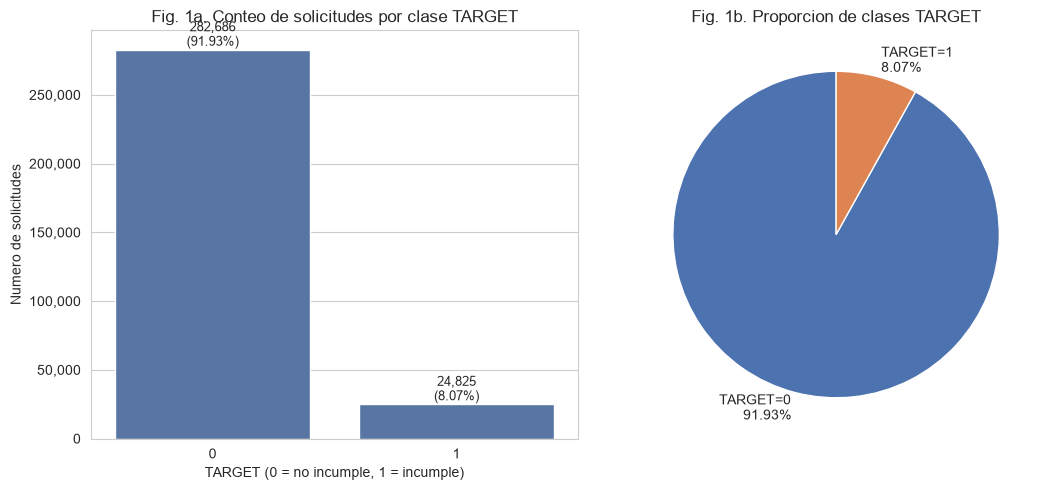

,clase,conteo,porcentaje
0,0,282686,91.93
1,1,24825,8.07


In [8]:
resumen_target = analysis.analizar_target()
resumen_target

### Interpretación de la Fig. 1

La clase `TARGET=0` (no incumple) representa **282.686 solicitudes (91,93%)** y la clase `TARGET=1` (incumple) representa **24.825 solicitudes (8,07%)** — una razón de aproximadamente **11,4 solicitudes que no incumplen por cada 1 que sí incumple**.

### ¿Están los datos balanceados?

No. El criterio operativo que usa este informe (Anexo 3 de `hw02-2026-2.docx`) es que una clase minoritaria por debajo del 10-20% del total ya constituye desbalance — aquí la clase minoritaria está en 8,07%, por debajo incluso del límite más estricto de ese rango. **Es un desbalance real y significativo, no marginal.**

### Qué es el balanceo de datos y cómo afecta los resultados

El balanceo de datos es el conjunto de técnicas que buscan corregir, en los datos de entrenamiento o en la función de pérdida del modelo, la disparidad en la cantidad de ejemplos entre clases, de forma que el algoritmo de aprendizaje no termine optimizando casi exclusivamente para la clase mayoritaria. El riesgo concreto de **no** balancear un dataset con esta proporción es que un modelo puede alcanzar una exactitud (*accuracy*) engañosamente alta (~92%) con la estrategia trivial de predecir siempre `TARGET=0` — porque el 92% de los casos reales son, en efecto, 0. Ese modelo sería inútil para el propósito real del negocio: identificar, de antemano, qué solicitudes tienen riesgo de incumplimiento. En términos de las métricas de clasificación, el desbalance típicamente hunde el *recall* y el *F1-score* de la clase minoritaria mientras la *precisión global* se mantiene artificialmente alta — exactamente el motivo por el que la competencia original de Kaggle evalúa con ROC-AUC (sensible al ranking de probabilidades entre clases) y no con *accuracy*.

**Postura propia:** en un problema de riesgo crediticio como este, el costo de los dos tipos de error no es simétrico — dejar pasar un cliente que va a incumplir (falso negativo) le cuesta dinero real a Home Credit, mientras que rechazar por error a un cliente que sí habría pagado (falso positivo) es un costo de oportunidad, pero no una pérdida directa. Esto sugiere que el balanceo no debería tratarse solo como un paso técnico para "limpiar" el desbalance estadístico, sino como una decisión alineada con esa asimetría de costos — preferir una técnica (o un ajuste de umbral posterior) que privilegie el *recall* de la clase `TARGET=1` sobre la precisión general, incluso a costa de más falsos positivos. Este criterio se retoma en la sección 7 (Balanceo de datos) para justificar la técnica elegida.

---
## `mainProcess` — punto de entrada único (código de producción)

Requisito literal del enunciado: el programa principal debe llamarse `mainProcess`. No se ejecuta en esta celda (repetiría toda la exploración de arriba) — se define aquí para que el notebook quede como fuente de verdad única; `report/main.tex` y `report/build_docx.py` reproducen este mismo código en la sección "Código Fuente" del informe.

In [9]:
def mainProcess():
    """
    Punto de entrada unico del analisis (Tarea 2).
    Pasos 1-3 implementados y verificados contra el dataset
    completo (307,511 x 122). Pasos 4-8 (calidad, limpieza,
    encoding, balanceo, ranking+PCA) en desarrollo -- ver
    hw02-2026-2.docx, seccion PROCEDIMIENTO.
    """
    analysis = HomeCreditAnalysis()
    analysis.cargar_datos()
    analysis.describir_dataset()
    analysis.analizar_target()

    # TODO paso 4: analysis.calidad_de_los_datos()
    # TODO paso 5: analysis.limpiar_datos()
    # TODO paso 6: analysis.convertir_categoricas()
    # TODO paso 7: analysis.balancear_clases()
    # TODO paso 8: analysis.ranking_atributos()

    return analysis


if __name__ == "__main__":
    pass  # ver nota arriba -- no se re-ejecuta en el notebook